# Case Study No. 2 (redone) — Hybrid Annualized Emissions for a Complex O&G Site

This notebook re-runs Case Study 2 end-to-end from **`Data_from_case_study_2.xlsx`** using the
EAMEET v1.0 event framework. It follows the paper's *measurement-campaign* temporal scenario
(Fig. 2c): the site is monitored for part of the year and unmonitored for the rest.

**Pipeline**
1. Merge the 4 observation types (CMS, Flyover, OGI, Operational) into **emission events** using
   the toolkit's rules (spatial matching + Allen's interval algebra).
2. **CMS PRE duration uncertainty** — CMS-derived durations carry large uncertainty (Daniels et al.
   2024); each CMS PRE duration is multiplied by a **log-uniform factor M between 0.5x and 2x**
   (symmetric about 1, so the point estimate is unchanged), giving a two-sided measured-emissions band.
3. **Measured window** → measured RE+PRE emissions (with CMS duration uncertainty) + below-MDL
   unresolved emissions (UEs) from `simulate_below_mdl()`.
4. **Unmeasured window** → `extrapolation()` (bootstrap) : simulated UEs for the unmonitored months.
5. **Sum** → full-year 2024 annualized total with 95% bounds. Results exported to CSV.

**Key modelling choices (see the CONFIG cell to change any of them)**
- Observations span **Jan–Apr 2024** for real measurement timestamps; the Flyover *detection time*
  column reaches **Jul 2024**. Per the analysis request, the **measured window is Jan 1 – Jul 31**
  (using flyover detection times) and the **bootstrap window is Aug 1 – Dec 31**.
- **Operational** events are **Resolved Events (RE)** whose quantity is inherited directly from the
  `total emissions (kg)` record (paper §2.1.1) — not merged/averaged, quantification only.
- **CMS / Flyover / OGI** are **Partially Resolved Events (PRE)**, merged **per equipment**
  (spatial matching = same feature of interest). OGI *true* detections carry no rate → used only as
  detection/null markers, not quantified.
- **CMS PREs** get the 0.5x–2x log-uniform duration multiplier above. **Flyover-only PREs** have their start/end
  *simulated* by the LPR/NRR duration workflow (§4) and the chosen statistic
  (`FLYOVER_DURATION_STAT`) is **adopted** into the emissions total; they remain flagged
  (`start_end_simulated = True`).
- Fitting: **Weibull** for the bootstrap rate/duration distributions.

> ⚠️ **Sensitivity to flag:** Flyover detections in May–Jul are bounded below by the last
> null-detection (OGI, Apr 1) and have no succeeding null-detection, so their **inferred PRE
> durations run to several months** — these are exactly the events flagged `start_end_simulated`.
> A single flyover snapshot can contribute hundreds of tonnes. Switch `USE_FLYOVER_DETECTION_TIME`
> to `False` (or shorten `MEASURED_END`) to test the Jan–Apr alternative.

In [1]:
# --- Environment setup ---
import sys, os, json
import multiprocessing as mp
try:
    mp.set_start_method("fork", force=True)   # macOS: avoid spawn re-import recursion in Pool
except RuntimeError:
    pass

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Point at the EAMEET_v1 application code
BASE = os.path.abspath(os.path.join(os.getcwd(), ".."))
APP  = os.path.join(BASE, "EAMEET_v1")
sys.path.insert(0, APP)

from emission_event_converter import convert_to_emission_event_model
from simulations import (simulate_below_mdl, extrapolation, sample_conditional_duration, null_repair_rate,
                         calculate_total_simulation_time_steps)
from utils import fitting_distribution

print("EAMEET app path:", APP)

EAMEET app path: /Users/mo/Desktop/Event-based-Annualized-Emissions-Estimation-Toolkit-main/EAMEET_v1


In [2]:
# ============================ CONFIG ============================
XLSX  = "Data_from_case_study_2.xlsx"          # source observations (this folder)
SITE  = "A"                                    # single site -> one below-MDL simulation
OUTDIR = "cs2_outputs"                          # figures + result files
os.makedirs(OUTDIR, exist_ok=True)

# Relative quantification uncertainty by technology (fraction of rate)
UNC_PCT = {"CMS": 0.40, "Flyover": 0.25, "Operational": 0.30}

# Temporal windows (measured Jan-Jul, bootstrap Aug-Dec)
MEASURED_START = pd.Timestamp("2024-01-01 00:00:00")
MEASURED_END   = pd.Timestamp("2024-07-31 23:59:59")
BOOT_START     = pd.Timestamp("2024-08-01 00:00:00")
YEAR_END       = pd.Timestamp("2024-12-31 23:59:59")

# Use flyover 'detection time' (reaches Jul); if False, uses 'survey time' (Jan-Apr)
USE_FLYOVER_DETECTION_TIME = True

# CMS PRE duration uncertainty -- DEFAULT ILLUSTRATIVE assumption, NOT a calibrated universal
# model. The Daniels et al. (2024) controlled-release performance is a starting prior only; real
# CMS duration error depends on sensor layout, meteorology, detection/quantification algorithm and
# site geometry. Multiplicative and SYMMETRIC about 1:  D_true = D_inferred x M,  M log-uniform
# (flat in log) centred on 1. CMS_DUR_MULT holds the 95% CI of M -> "within a factor of two"
# = 0.5x to 2x, in EITHER direction (not an additive 0-to-+200% one-sided inflation).
CMS_DUR_MULT   = (0.5, 2.0)
MC_DUR         = 2000          # (reserved; CMS PRE emission bounds are analytical -- see section 5)

# Below-MDL: CMS-class technology from the toolkit library; wind off (POD/MDL constants)
CMS_TECH       = "Qube"
CONSIDER_WIND  = False
# Coverage schedule of the CMS. The uptime log of the Site A CMS is not available, so the CMS is assumed to
# have been observing throughout the measured window (None). A list of (start, end) uptime intervals can be
# supplied instead; the time budget then becomes (uptime hours) - (hours occupied by observed events).
CMS_COVERAGE   = None
MC_MEASURED    = 10_000       # below-MDL Monte Carlo iterations (>= 10,000, as stated in the Methodology)

# Bootstrap
BOOT_FIT       = "weibull"     # rate & duration distribution family for the bootstrap
MC_BOOT        = 10_000       # bootstrap Monte Carlo iterations (>= 10,000)

# Reproducibility: the UE sims (simulate_below_mdl / extrapolation) draw their per-worker
# seeds from the GLOBAL numpy RNG, so seeding it right before each call makes totals repeatable.
SEED_UE        = 99

# Flyover-only PRE duration simulation (LPR/NRR workflow)
LPR            = 0.006          # leak production rate (leaks/day/site) — paper default (Kemp 2016)
# Null-repair rate (Fox et al. 2021, SI Eq. S1): NRR = (LPR*V/Lbar0)*(Lt/L0) + p_max*Q_i/Q_max,
# the probability that an operator detects & repairs the leak during ONE site visit (every V days).
P_MAX               = 0.25      # 'operator bonus' for the largest source; LDAR-Sim explores 0-0.25
VISIT_INTERVAL_DAYS = 7         # V: weekly operator visits -> NRR is a per-VISIT probability
LEAKS_PER_SITE      = 10        # Lbar0 (mean leaks per site at steady state); Lt/L0 = 1
NRR_OVERRIDE        = None      # None -> Eq. S1 above; else a per-visit probability
# Succeeding bound: no null detection follows the last flyover detection. The cessation is capped at
# the END OF THE MONITORED WINDOW (Aug-Dec is simulated by the bootstrap, so extending past it would
# double count). SND_EXTENSION_DAYS (last detection + N d) is kept as a sensitivity alternative.
SND_CAP            = "measured_end"   # "measured_end" | "extension"
SND_EXTENSION_DAYS = 90
N_DUR_SIM      = 100_000        # Monte-Carlo draws for the duration workflow
# Which simulated statistic replaces the flyover PRE duration in the emissions total:
#   "estimated" (naive null-detect bracket) | "median" | "mean"
FLYOVER_DURATION_STAT = "median"
# Null-detection validity (SOFT bounds). A null detection only bounds the event if the survey
# would have detected the emission: each preceding null is a valid bound with probability POD,
# otherwise the bound falls back to the next null outward and finally to MEASURED_START.
# 0.9 = the toolkit's default flat POD plateau for survey technologies; set 1.0 for hard bounds.
NULL_POD = {"ogi": 0.9, "flyover": 0.9}

print("Config loaded. Measured:", MEASURED_START.date(), "->", MEASURED_END.date(),
      "| Bootstrap:", BOOT_START.date(), "->", YEAR_END.date())

Config loaded. Measured: 2024-01-01 -> 2024-07-31 | Bootstrap: 2024-08-01 -> 2024-12-31


## 1. Load observations and build the unified measurement table

In [3]:
xls = pd.ExcelFile(XLSX)
cms = xls.parse("CMS"); ogi = xls.parse("OGI"); fly = xls.parse("Flyover"); op = xls.parse("Operational")
print("CMS:", cms.shape, "| OGI:", ogi.shape, "| Flyover:", fly.shape, "| Operational:", op.shape)

rows = []
# CMS -> PRE, measured start/end, source = equipment
for _, r in cms.iterrows():
    rate = float(r["rate (kg/hr)"])
    rows.append(dict(id=r["ID"], source=str(r["equipment"]), rate=rate,
                     uncertainties=UNC_PCT["CMS"]*rate,
                     start_time=pd.to_datetime(r["start time"]), end_time=pd.to_datetime(r["end time"]),
                     time=pd.to_datetime(r["start time"]), observation_type="cms"))

# Flyover -> PRE, facility scale; detection time (or survey time); non-detection -> null-detect
for _, r in fly.iterrows():
    if bool(r["detection"]):
        if USE_FLYOVER_DETECTION_TIME and pd.notna(r["detection time"]):
            t = pd.to_datetime(r["detection time"])
        else:
            t = pd.to_datetime(r["survey time"])
        rate = float(r["rate (kg/hr)"])
        rows.append(dict(id=r["ID"], source="Facility", rate=rate,
                         uncertainties=UNC_PCT["Flyover"]*rate,
                         start_time=pd.NaT, end_time=pd.NaT, time=t, observation_type="flyover"))
    else:
        rows.append(dict(id=r["ID"], source="Facility", rate=0.0, uncertainties=0.0,
                         start_time=pd.NaT, end_time=pd.NaT,
                         time=pd.to_datetime(r["survey time"]), observation_type="flyover"))

# OGI -> only non-detections as null-detect bounding markers; true detections lack a rate -> excluded
ogi_excluded = []
for _, r in ogi.iterrows():
    if not bool(r["detection"]):
        rows.append(dict(id=r["ID"], source="Facility", rate=0.0, uncertainties=0.0,
                         start_time=pd.NaT, end_time=pd.NaT,
                         time=pd.to_datetime(r["survey time"]), observation_type="ogi"))
    else:
        ogi_excluded.append(r["ID"])

obs = pd.DataFrame(rows)
print("\nMeasurement observations:", obs.shape,
      "| detections:", int((obs.rate > 0).sum()),
      "| null-detects:", int((obs.rate == 0).sum()))
print("OGI true-detections excluded (no quantified rate):", ogi_excluded)
obs.head()

CMS: (89, 6) | OGI: (4, 6) | Flyover: (4, 6) | Operational: (10, 6)

Measurement observations: (95, 8) | detections: 92 | null-detects: 3
OGI true-detections excluded (no quantified rate): ['OGI-2', 'OGI-3']


,id,source,rate,uncertainties,start_time,end_time,time,observation_type
0,CMS-1,Separator-1,29.863096,11.945239,2024-04-29 23:25:00,2024-04-30 04:48:00,2024-04-29 23:25:00,cms
1,CMS-10,Separator-1,24.535003,9.814001,2024-04-17 05:04:00,2024-04-17 14:09:00,2024-04-17 05:04:00,cms
2,CMS-11,Separator-1,13.041631,5.216653,2024-04-16 04:25:00,2024-04-16 10:40:00,2024-04-16 04:25:00,cms
3,CMS-12,Separator-1,9.677584,3.871033,2024-04-16 04:25:00,2024-04-16 10:40:00,2024-04-16 04:25:00,cms
4,CMS-13,Separator-1,16.014934,6.405974,2024-04-14 01:54:00,2024-04-14 05:54:00,2024-04-14 01:54:00,cms


## 2. Convert to emission events (PRE = measurements merged per equipment; RE = operational)

In [4]:
# 2a. CMS / Flyover / OGI -> PRE events (Allen's interval algebra, grouped by equipment)
mapping = {"rate":"rate","id":"id","source":"source","uncertainties":"uncertainties",
           "start_time":"start_time","end_time":"end_time","time":"time",
           "observation_type":"observation_type"}
pre_events = convert_to_emission_event_model(obs, column_mapping=mapping, time_column="time",
                                             emission_characteristics="intermittent")
pre_events["event_type"] = "PRE"
pre_events["equipment"]  = pre_events["sourceLocation"]

# 2b. Operational -> standalone RE events; quantity inherited directly from the record
re_rows = []
for _, r in op.iterrows():
    st, et = pd.to_datetime(r["start time"]), pd.to_datetime(r["end time"])
    dur_h  = (et - st).total_seconds() / 3600
    qty    = float(r["total emissions (kg)"])
    rate   = qty / dur_h if dur_h > 0 else qty
    re_rows.append(dict(id=str(r["ID"]), rate=rate, duration=dur_h, quantity=qty,
                        sourceLocation=SITE, startTime=st.isoformat(), endTime=et.isoformat(),
                        merged_from=str(r["ID"]), event_type="RE",
                        uncertainties=UNC_PCT["Operational"]*rate, equipment=str(r["equipment"])))
re_events = pd.DataFrame(re_rows)

# 2c. Combine and relabel to the single site for a site-level simulation
events = pd.concat([pre_events, re_events], ignore_index=True)
events = events.rename(columns={"equipment": "equipment_of_record"})
events["sourceLocation"] = SITE

# Classify observation kind from the merged original ids
def obs_kind(row):
    if row["event_type"] == "RE":
        return "Operational"
    mf = str(row["merged_from"])
    has_cms, has_fly = "CMS" in mf, "FLY" in mf
    if has_cms and not has_fly: return "CMS"
    if has_fly and not has_cms: return "Flyover"
    if has_cms and has_fly:     return "Mixed"
    return "Other"
events["obs_kind"] = events.apply(obs_kind, axis=1)

# Flags follow the paper rule, robust to mixed PREs:
#   * ANY PRE containing a CMS observation  -> log-uniform 0.5x-2x duration multiplier (incl. CMS+flyover mixed)
#   * a PRE built ONLY from flyover snapshots -> start/end simulated from bracketing null-detects
_is_pre  = events["event_type"].eq("PRE")
_has_cms = events["merged_from"].astype(str).str.contains("CMS")
_has_fly = events["merged_from"].astype(str).str.contains("FLY")
events["duration_uncertainty_applied"] = _is_pre & _has_cms                # CMS-containing PRE (incl. mixed)
events["start_end_simulated"]          = _is_pre & _has_fly & ~_has_cms    # flyover-only PRE

n_re  = int((events.event_type == "RE").sum())
n_pre = int((events.event_type == "PRE").sum())
print(f"Events: {len(events)}  |  RE: {n_re}  |  PRE: {n_pre}")
print("PRE breakdown by obs kind:", events[events.event_type=='PRE']['obs_kind'].value_counts().to_dict())
print(f"Flagged start_end_simulated (flyover PREs): {int(events.start_end_simulated.sum())}")
print(f"Flagged duration_uncertainty_applied (CMS PREs): {int(events.duration_uncertainty_applied.sum())}")
print(f"\nBase quantity: RE {events[events.event_type=='RE'].quantity.sum():,.1f} kg | "
      f"PRE {events[events.event_type=='PRE'].quantity.sum():,.1f} kg")
events[["id","equipment_of_record","obs_kind","rate","duration","quantity",
        "event_type","start_end_simulated","duration_uncertainty_applied"]].head()

Events: 86  |  RE: 10  |  PRE: 76
PRE breakdown by obs kind: {'CMS': 75, 'Flyover': 1}
Flagged start_end_simulated (flyover PREs): 1
Flagged duration_uncertainty_applied (CMS PREs): 75

Base quantity: RE 2,453.5 kg | PRE 373,062.2 kg


,id,equipment_of_record,obs_kind,rate,duration,quantity,event_type,start_end_simulated,duration_uncertainty_applied
0,774a219f-aac0-43d3-9afe-8f141a27487e,Compressor-2,CMS,11.053783,7.333333,81.061078,PRE,False,True
1,3e8165cd-090e-486c-bf65-3f3facba555c,Compressor-2,CMS,127.139873,18.333333,2330.897674,PRE,False,True
2,ee7d6361-8215-4a9e-926d-a725521c6c58,Compressor-2,CMS,9.865366,60.766667,599.485384,PRE,False,True
3,a74b65f2-bb24-48c2-93b8-fcd3b1430905,Compressor-2,CMS,7.280364,16.766667,122.067444,PRE,False,True
4,a913dde7-90eb-41e7-9189-dcc88a883a20,Compressor-2,CMS,18.511806,13.316667,246.515552,PRE,False,True


## 3. Diagnostics — where do the emissions concentrate?

The largest measured contributions come from flyover PREs whose duration is inferred from sparse
null-detections. Inspect them here before trusting the totals.

In [5]:
ev_sorted = events.sort_values("quantity", ascending=False)
print("Top 8 events by emission quantity:")
print(ev_sorted[["id","equipment_of_record","event_type","rate","duration","quantity"]].head(8).to_string(index=False))

# Flyover events specifically (ids start with FLY)
fly_ev = events[events["merged_from"].astype(str).str.contains("FLY")]
print("\nFlyover-derived events (note multi-month inferred durations):")
print(fly_ev[["merged_from","rate","duration","quantity"]].to_string(index=False))
print(f"\nFlyover share of PRE quantity: "
      f"{fly_ev.quantity.sum()/events[events.event_type=='PRE'].quantity.sum():.1%}")

Top 8 events by emission quantity:
                                  id equipment_of_record event_type       rate    duration      quantity
d6d8e075-173a-44f6-a84c-3499b7d82b22            Facility        PRE 152.246667 2284.000000 347731.386667
c25ae03e-62ab-41da-b657-5ac2e250f0fe        Dehydrator-1        PRE  38.175578   75.550000   2884.164897
3e8165cd-090e-486c-bf65-3f3facba555c        Compressor-2        PRE 127.139873   18.333333   2330.897674
52040833-1bef-4ab3-b81a-97ccb7a50c99        Dehydrator-1        PRE 123.332861   13.883333   1712.271226
45a31781-9388-4b31-b3c4-4c6605a24b6e         Separator-1        PRE  77.631961   20.116667   1561.696282
d21d5821-9fe7-4424-a69b-28d2aa102e73         Separator-2        PRE 140.624127    9.766667   1373.428978
78fe97f2-608f-4a9a-b639-f4fcfc4c980f        Compressor-3        PRE  50.813488   15.366667    780.833928
e512821f-0f67-4c8e-8f34-e2c547f6286c        Dehydrator-1        PRE  60.479705   10.250000    619.916976

Flyover-derived eve

## 4. Simulate start/end times for flyover-only PREs (conditional-on-detection)

Flyover-only PREs have start/end *inferred* (flagged `start_end_simulated`). A flyover
**detection is evidence the emission was active at that time**, so we infer duration
*conditional on the detection(s)* rather than filling the null-detection bracket. Every
realization satisfies **t_PND ≤ t_start ≤ t_first** and **t_last ≤ t_end ≤ t_SND**:

1. Every Monte-Carlo realization **contains the detection span** `[t_first, t_last]` -- the
   emission is never assumed absent.
2. **Onset** is sampled backward from the first detection: `t_start = t_first - a`, with
   density(a) ∝ `exp[-(lambda_off - lambda_on) a]` **truncated** to `[0, t_first - t_PND]`.
   The onset hazard says how soon a leak begins after the preceding null; the
   `exp(-lambda_off a)` factor is the probability it **survived unrepaired** until it was
   first seen. (The earlier `a ~ Exp(lambda_on)` draw omitted the survival term.)
3. **Cessation** is sampled forward from the last detection: `t_end = t_last + b`, with
   `b ~ Exp(lambda_off)` **truncated** to `[0, t_SND - t_last]` (memoryless lifetime). As no
   succeeding null detection exists, `t_SND` = end of the monitored window (31 Jul); Aug-Dec is
   simulated by the bootstrap, so extending past it would double count. (`last detection + 90 d`
   is reported as a sensitivity case.)
4. **Soft null-detection bounds.** A null detection only proves absence if the survey would have
   seen the emission. In each iteration the nearest preceding null (OGI-4, 1 Apr) is a valid
   bound with probability `NULL_POD`; otherwise the bound falls back outward along the chain of
   earlier nulls (FLY-1, 7 Jan; OGI-1, 1 Jan) and finally to the measured-window start.
5. `lambda_on` is the per-hour hazard of the per-day **LPR** (`-ln(1 - LPR)/24`). `lambda_off` is the
   per-hour hazard of the **null-repair rate** of Fox et al. (2021, SI Eq. S1),
   `NRR = (LPR*V/Lbar0)*(Lt/L0) + p_max*Q_i/Q_max`, which is the probability that an operator
   detects and repairs the leak during ONE site visit every `V = 7` days, so
   `lambda_off = -ln(1 - NRR)/(24*V)`. (`p_max = 0.25`, the top of the LDAR-Sim range; `Lbar0 = 10`.)

This replaces the earlier **daily LPR/NRR bracket-filling** draw, whose `no_leak` fallback
set start/end to the full bracket and pinned inferred durations to the upper boundary.
Repeat **N = 10^5** times -> simulated start/end and their 95% intervals.


In [6]:
# 4. Flyover-only PRE duration -- CONDITIONAL-ON-DETECTION model (revised)
# --------------------------------------------------------------------------------
# Replaces the former daily LPR/NRR bracket-filling draw. That model stepped in DAYS and,
# whenever no leak was sampled within the window, set start=bracket-start & end=bracket-end
# -- i.e. "no simulated onset" became "emitting the entire interval", pinning inferred
# durations to the upper boundary. A flyover DETECTION is evidence the emission was active,
# so here every realization is constructed to CONTAIN the detection span
# [first_detection, last_detection]; we sample only how far the emission extends BEFORE the
# first and AFTER the last detection, in continuous time, from truncated-exponential hazards
# (rates = the continuous-time equivalents of the per-day LPR / NRR). See
# simulations.sample_conditional_duration.
#
# Succeeding bound: there is no null detection after the last flyover detection, so we cap
# cessation at t_SND = last_detection + SND_EXTENSION_DAYS (analysis choice, see caveats).


def _flyover_detection_times(merged_from):
    """First/last detection timestamps of the source flyovers merged into this PRE."""
    ids = [s.strip() for s in str(merged_from).split(",")]
    sub = fly[fly["ID"].astype(str).isin(ids) & fly["detection"].astype(bool)]
    if USE_FLYOVER_DETECTION_TIME:
        t = sub["detection time"].where(sub["detection time"].notna(), sub["survey time"])
    else:
        t = sub["survey time"]
    t = pd.to_datetime(t).dropna().sort_values()
    return t.iloc[0], t.iloc[-1]

Q_max_pre = float(events.loc[events.event_type == "PRE", "rate"].max())
SIM_COLS = ["sim_start_time","sim_start_lo","sim_start_hi","sim_end_time","sim_end_lo","sim_end_hi",
            "sim_duration_h","sim_duration_mean_h","sim_duration_lo","sim_duration_hi"]
EST_COLS = ["estimated_start","estimated_end","estimated_duration_h","estimated_quantity"]
for c in SIM_COLS + [x for x in EST_COLS if x not in ("estimated_duration_h","estimated_quantity")]:
    _is_dt = c.startswith("sim_start") or c.startswith("sim_end") or c in ("estimated_start","estimated_end")
    events[c] = pd.NaT if _is_dt else np.nan
for c in ("estimated_duration_h","estimated_quantity"):
    events[c] = np.nan

fly_mask = events["start_end_simulated"]   # flyover-only PREs (see flag rule in section 2)
FLY_DUR_SAMPLES = {}   # idx -> raw duration draws (h) for joint MC propagation
print(f"Simulating start/end for {int(fly_mask.sum())} flyover-only PRE(s) | "
      f"LPR={LPR}/day, NRR: Eq. S1 (p_max={P_MAX}, V={VISIT_INTERVAL_DAYS} d, {LEAKS_PER_SITE} leaks/site), "
      f"Q_max(PRE)={Q_max_pre:.1f}, N={N_DUR_SIM:,}")
print(f"Model: conditional-on-detection (continuous-time truncated hazards, backward rate = NRR - LPR); "
      f"t_SND = {'end of monitored window' if SND_CAP == 'measured_end' else f'last detection + {SND_EXTENSION_DAYS} d'}; "
      f"null-detection POD {NULL_POD}.")
print(f"Adopting FLYOVER_DURATION_STAT = '{FLYOVER_DURATION_STAT}' into the emissions total.\n")
for i, idx in enumerate(events.index[fly_mask]):
    e = events.loc[idx]
    t_first, t_last = _flyover_detection_times(e["merged_from"])
    # Preceding null detections (nearest first) with their PODs. The nearest one is the
    # bracket start t_PND; each is a VALID bound only with probability POD, otherwise the
    # bound falls back to the next null outward and finally to MEASURED_START (soft bounds).
    nulls = obs[(obs.rate == 0) & (obs.time < t_first)].sort_values("time", ascending=False)
    pnd_chain = [(pd.to_datetime(n.time), NULL_POD[n.observation_type]) for n in nulls.itertuples()]
    t_pnd, pnd_pod = pnd_chain[0] if pnd_chain else (MEASURED_START, 1.0)
    pnd_fallbacks = pnd_chain[1:]
    assert abs((t_pnd - pd.to_datetime(e["startTime"])).total_seconds()) < 60, "bracket start != nearest null"
    # Succeeding bound: no later null detection -> cap at the end of the monitored window (default) or
    # at last detection + SND_EXTENSION_DAYS (sensitivity alternative)
    t_snd = MEASURED_END if SND_CAP == "measured_end" else t_last + pd.to_timedelta(SND_EXTENSION_DAYS, unit="D")
    rate  = e["rate"]
    NRR   = NRR_OVERRIDE if NRR_OVERRIDE is not None else null_repair_rate(
                LPR, rate, Q_max_pre, p_max=P_MAX, visit_interval_days=VISIT_INTERVAL_DAYS, leaks_per_site=LEAKS_PER_SITE)
    r = sample_conditional_duration(t_first, t_last, t_pnd, t_snd, LPR=LPR, NRR=NRR,
                                    N=N_DUR_SIM, seed=i,
                                    pnd_pod=pnd_pod, pnd_fallbacks=pnd_fallbacks, pnd_floor=MEASURED_START,
                                    nrr_interval_days=VISIT_INTERVAL_DAYS)
    for c in SIM_COLS:
        events.at[idx, c] = r[c]
    FLY_DUR_SAMPLES[idx] = r["dur_samples"]
    est_dur, est_q = e["duration"], e["quantity"]
    print(f"Event {e['merged_from']}  (rate {e['rate']:.1f} kg/hr, NRR {NRR:.3f} per {VISIT_INTERVAL_DAYS}-day visit)")
    print(f"  detections        : {t_first.date()} -> {t_last.date()}  (span {r['det_span_h']/24:.0f} d); "
          f"PND {t_pnd.date()}, SND {t_snd.date()}")
    print(f"  hazards /h        : on {r['lam_on_per_hr']:.5f}, off {r['lam_off_per_hr']:.5f}, "
          f"backward (off-on) {r['lam_back_per_hr']:.5f}")
    print(f"  PND chain (POD)   : " + ", ".join(f"{t.date()} ({p:.2f})" for t, p in pnd_chain)
          + f"; floor {MEASURED_START.date()} | nearest PND valid in {r['pnd_valid_frac']:.1%} of draws")
    print(f"  estimated bracket : {pd.to_datetime(e['startTime']).date()} -> {pd.to_datetime(e['endTime']).date()}  ({est_dur:.0f} h, {est_q/1000:.1f} t)")
    print(f"  simulated START   : {r['sim_start_time'].date()}  95% [{r['sim_start_lo'].date()}, {r['sim_start_hi'].date()}]")
    print(f"  simulated END     : {r['sim_end_time'].date()}  95% [{r['sim_end_lo'].date()}, {r['sim_end_hi'].date()}]")
    print(f"  simulated duration: median {r['sim_duration_h']:.0f} h | mean {r['sim_duration_mean_h']:.0f} h | "
          f"95% [{r['sim_duration_lo']:.0f}, {r['sim_duration_hi']:.0f}] h")

    # ---- Adopt the chosen simulated statistic into the flyover PRE quantity/bounds ----
    events.at[idx, "estimated_start"]       = e["startTime"]
    events.at[idx, "estimated_end"]         = e["endTime"]
    events.at[idx, "estimated_duration_h"]  = est_dur
    events.at[idx, "estimated_quantity"]    = est_q
    if FLYOVER_DURATION_STAT != "estimated":
        new_dur   = r["sim_duration_mean_h"] if FLYOVER_DURATION_STAT == "mean" else r["sim_duration_h"]
        new_start = r["sim_start_time"].floor("s")
        new_end   = (new_start + pd.to_timedelta(new_dur, unit="h")).floor("s")
        events.at[idx, "duration"]  = new_dur
        events.at[idx, "quantity"]  = e["rate"] * new_dur
        events.at[idx, "startTime"] = new_start.isoformat()
        events.at[idx, "endTime"]   = new_end.isoformat()
        print(f"  ADOPTED ({FLYOVER_DURATION_STAT}): {new_dur:.0f} h -> {e['rate']*new_dur/1000:.1f} t "
              f"(was {est_q/1000:.1f} t; start {new_start.date()} -> end {new_end.date()})")

print(f"\nPRE quantity after adoption: {events[events.event_type=='PRE'].quantity.sum()/1000:.1f} t")
events.loc[fly_mask, ["merged_from","estimated_duration_h","duration","estimated_quantity","quantity"]]


Simulating start/end for 1 flyover-only PRE(s) | LPR=0.006/day, NRR: Eq. S1 (p_max=0.25, V=7 d, 10 leaks/site), Q_max(PRE)=152.2, N=100,000
Model: conditional-on-detection (continuous-time truncated hazards, backward rate = NRR - LPR); t_SND = end of monitored window; null-detection POD {'ogi': 0.9, 'flyover': 0.9}.
Adopting FLYOVER_DURATION_STAT = 'median' into the emissions total.

Event FLY-2, FLY-3, FLY-4  (rate 152.2 kg/hr, NRR 0.254 per 7-day visit)
  detections        : 2024-05-22 -> 2024-07-05  (span 44 d); PND 2024-04-01, SND 2024-07-31
  hazards /h        : on 0.00025, off 0.00175, backward (off-on) 0.00150
  PND chain (POD)   : 2024-04-01 (0.90), 2024-01-07 (0.90), 2024-01-01 (0.90); floor 2024-01-01 | nearest PND valid in 90.0% of draws
  estimated bracket : 2024-04-01 -> 2024-07-05  (2284 h, 347.7 t)
  simulated START   : 2024-05-07  95% [2024-04-03, 2024-05-22]
  simulated END     : 2024-07-15  95% [2024-07-06, 2024-07-30]
  simulated duration: median 1711 h | mean 1772 h

,merged_from,estimated_duration_h,duration,estimated_quantity,quantity
48,"FLY-2, FLY-3, FLY-4",2284.0,1710.820618,347731.386667,260466.736313


## 5. Measured emissions with per-event quantification + duration uncertainty (Eqs. 3, 6, 10-11)

Each event's **quantification uncertainty** (technology-specific: CMS 40 %, flyover 25 %, operational
30 %) and **duration uncertainty** are combined in quadrature per event (Eq. 6,
`U_E = E * sqrt((U_Q/Q)^2 + (U_D/D)^2)`, one-sided each way), and the events are then aggregated in
**quadrature** (root-sum-square, Eqs. 10-11):

- **CMS PRE** — point = the *measured* emission (rate x measured duration). Relative duration
  uncertainty from the log-uniform multiplier M (95% CI 0.5x-2x, symmetric about 1): +1.0 / -0.5.
- **Flyover PRE** — point = the adopted (median) quantity; relative duration uncertainty from the
  LPR/NRR duration simulation CI (asymmetric).
- **RE (operational)** — point = recorded quantity; quantification uncertainty only (Eq. 3).

> Note: RSS of *independent* per-event errors necessarily narrows the aggregate (~1/sqrt(N)); the CMS
> band is small by construction even though each event spans a factor of two. A correlated (systematic)
> bias would instead sum linearly — reported alongside as the "systematic" alternative.


In [7]:
# --- Measured-window emissions: analytical error propagation (Eqs. 3, 6, 10-11) ---------
# Per event, the technology-specific QUANTIFICATION uncertainty (events['uncertainties'], a fraction
# of the rate) and the DURATION uncertainty are combined in quadrature (Eq. 6), one-sided each way;
# events are then aggregated in quadrature (RSS, Eqs. 10-11). REs carry quantification only (Eq. 3).
#   * CMS PRE     : point = measured (rate x dur); M log-uniform, symmetric about 1 -> rel. duration
#                   unc. +(M_hi-1) / -(1-M_lo) = +1.0 / -0.5.
#   * Flyover PRE : point = adopted (median) quantity; rel. duration unc. from the sim duration CI.
#   * RE          : point = recorded quantity; rel. quantification unc. only.
m_lo, m_hi = CMS_DUR_MULT                   # (0.5, 2.0) -> 95% CI of the multiplier M, centred on 1

cms_m = events["duration_uncertainty_applied"].to_numpy()
fly_m = events["start_end_simulated"].to_numpy()
re_m  = (events["event_type"] == "RE").to_numpy()

# Relative quantification uncertainty per event (falls back to UNC_PCT by observation kind)
_kind2pct = {"CMS": UNC_PCT["CMS"], "Mixed": UNC_PCT["CMS"], "Flyover": UNC_PCT["Flyover"],
             "Operational": UNC_PCT["Operational"]}
rel_q = (events["uncertainties"] / events["rate"]).to_numpy(float)
rel_q = np.where(np.isfinite(rel_q), rel_q, events["obs_kind"].map(_kind2pct).to_numpy(float))
events["rel_quant_unc"] = rel_q

def _eq6(point, rq, rel_d_up, rel_d_dn):
    """Eq. 6: per-event emission uncertainty E*sqrt((U_Q/Q)^2 + (U_D/D)^2), upper and lower."""
    return point * np.sqrt(rq ** 2 + rel_d_up ** 2), point * np.sqrt(rq ** 2 + rel_d_dn ** 2)

# ---- CMS PREs ----
cms_base = (events.loc[cms_m, "rate"] * events.loc[cms_m, "duration"]).to_numpy(float)  # measured (M=1)
cms_pt_i = cms_base
cms_up_i, cms_dn_i = _eq6(cms_pt_i, rel_q[cms_m], m_hi - 1.0, 1.0 - m_lo)
cms_meas = float(cms_pt_i.sum())
cms_up   = float(np.sqrt(np.sum(cms_up_i ** 2)))     # RSS (quadrature)
cms_dn   = float(np.sqrt(np.sum(cms_dn_i ** 2)))
cms_lo, cms_hi = cms_meas - cms_dn, cms_meas + cms_up
# "systematic" alternative: an error shared by all CMS events sums linearly instead of in quadrature
cms_sys_lo, cms_sys_hi = cms_meas - float(cms_dn_i.sum()), cms_meas + float(cms_up_i.sum())

# ---- Flyover PREs ----
fly_pt_i = events.loc[fly_m, "quantity"].to_numpy(float)
fly_d_lo = (events.loc[fly_m, "rate"] * events.loc[fly_m, "sim_duration_lo"]).to_numpy(float)
fly_d_hi = (events.loc[fly_m, "rate"] * events.loc[fly_m, "sim_duration_hi"]).to_numpy(float)
fly_rel_up = np.maximum(0.0, fly_d_hi - fly_pt_i) / fly_pt_i
fly_rel_dn = np.maximum(0.0, fly_pt_i - fly_d_lo) / fly_pt_i
fly_up_i, fly_dn_i = _eq6(fly_pt_i, rel_q[fly_m], fly_rel_up, fly_rel_dn)
fly_meas = float(fly_pt_i.sum())
fly_up   = float(np.sqrt(np.sum(fly_up_i ** 2)))
fly_dn   = float(np.sqrt(np.sum(fly_dn_i ** 2)))
fly_lo, fly_hi = fly_meas - fly_dn, fly_meas + fly_up

# ---- REs (Eq. 3): quantification uncertainty only ----
re_pt_i = events.loc[re_m, "quantity"].to_numpy(float)
re_up_i = re_dn_i = re_pt_i * rel_q[re_m]
re_meas  = float(re_pt_i.sum())
re_up = re_dn = float(np.sqrt(np.sum(re_up_i ** 2)))
re_lo, re_hi = re_meas - re_dn, re_meas + re_up
re_fixed = re_meas   # name kept for downstream cells

# ---- Persist per-event emission bounds (for the CSV / inspection) ----
events["emis_point"] = np.nan; events["emis_lo"] = np.nan; events["emis_hi"] = np.nan
for _mask, _pt, _dn, _up in ((cms_m, cms_pt_i, cms_dn_i, cms_up_i),
                             (fly_m, fly_pt_i, fly_dn_i, fly_up_i),
                             (re_m,  re_pt_i,  re_dn_i,  re_up_i)):
    events.loc[_mask, "emis_point"] = _pt
    events.loc[_mask, "emis_lo"]    = _pt - _dn
    events.loc[_mask, "emis_hi"]    = _pt + _up

# ---- Aggregate measured events in quadrature (Eqs. 10-11) ----
pre_up = float(np.sqrt(cms_up ** 2 + fly_up ** 2))
pre_dn = float(np.sqrt(cms_dn ** 2 + fly_dn ** 2))
measured    = re_meas + cms_meas + fly_meas
measured_dn = float(np.sqrt(re_dn ** 2 + pre_dn ** 2))
measured_up = float(np.sqrt(re_up ** 2 + pre_up ** 2))
measured_lo = measured - measured_dn
measured_hi = measured + measured_up

print(f"RE  (operational; Q unc. {UNC_PCT['Operational']:.0%}, RSS):              {re_meas/1000:7.2f} t  [{re_lo/1000:.2f}, {re_hi/1000:.2f}]")
print(f"CMS PRE (Q unc. {UNC_PCT['CMS']:.0%} + M~logU[{m_lo},{m_hi}] dur., RSS):   {cms_meas/1000:7.2f} t  [{cms_lo/1000:.2f}, {cms_hi/1000:.2f}]  (RSS of {int(cms_m.sum())} PREs; systematic alt. [{cms_sys_lo/1000:.2f}, {cms_sys_hi/1000:.2f}])")
print(f"Flyover PRE (Q unc. {UNC_PCT['Flyover']:.0%} + sim-duration CI):          {fly_meas/1000:7.2f} t  [{fly_lo/1000:.2f}, {fly_hi/1000:.2f}]")
print(f"Measured RE+PRE (all events in quadrature):          {measured/1000:7.2f} t  [{measured_lo/1000:.2f}, {measured_hi/1000:.2f}]")


RE  (operational; Q unc. 30%, RSS):                 2.45 t  [2.18, 2.73]
CMS PRE (Q unc. 40% + M~logU[0.5,2.0] dur., RSS):     25.33 t  [22.05, 30.85]  (RSS of 75 PREs; systematic alt. [9.18, 52.57])
Flyover PRE (Q unc. 25% + sim-duration CI):           260.47 t  [169.61, 407.13]
Measured RE+PRE (all events in quadrature):           288.25 t  [197.33, 435.02]


## 6. Undetected emissions during the **measured** window (Jan–Jul): POD-based simulation

Time budget = hours of the measured window in which the CMS was observing (`CMS_COVERAGE`, here the
whole window) **minus the union of the hours already occupied by observed events** (REs and PREs),
so emissions represented by measured events are not simulated a second time. Hypothetical events
(component-scale rate x component count, empirical durations) tile these gap hours and each is missed
with probability 1 - POD(Q); misses above the nominal MDL are therefore possible. The superseded v1.0
budget (the *sum* of observed-event durations) is printed for comparison.


In [8]:
ev = events.copy()
ev["source"]     = ev["sourceLocation"]
ev["start_time"] = pd.to_datetime(ev["startTime"], format="ISO8601").dt.strftime("%Y-%m-%d %H:%M:%S")
ev["end_time"]   = pd.to_datetime(ev["endTime"], format="ISO8601").dt.strftime("%Y-%m-%d %H:%M:%S")

# Time budget of the POD-based simulation (gap hours) vs the superseded sum-of-event-durations budget
cov = None if CMS_COVERAGE is None else {CMS_TECH: CMS_COVERAGE}
budget_h = calculate_total_simulation_time_steps(ev, MEASURED_START, MEASURED_END, coverage=CMS_COVERAGE)
legacy_h = calculate_total_simulation_time_steps(ev, MEASURED_START, MEASURED_END, mode="observed_event_hours")
window_h = (MEASURED_END - MEASURED_START).total_seconds()/3600
print(f"Measured window {window_h:,.0f} h; observed events occupy {window_h-budget_h:,.0f} h; "
      f"POD-simulation budget = {budget_h:,.0f} gap h  (superseded v1.0 budget: {legacy_h:,.0f} h = sum of event durations)")

# We use only the UE component from this call; measured comes from the MC above.
np.random.seed(SEED_UE)   # reproducible UE
res = simulate_below_mdl(ev, MEASURED_START, MEASURED_END, mc_iterations=MC_MEASURED,
                         technologies=[CMS_TECH], consider_wind=CONSIDER_WIND, coverage=cov)
(_, _, _, _, _, _, ue_mdl, ue_mdl_lo, ue_mdl_hi) = res

print(f"UE below-MDL: {ue_mdl/1000:8.2f} t   [{ue_mdl_lo/1000:.2f}, {ue_mdl_hi/1000:.2f}]")

Measured window 5,112 h; observed events occupy 2,881 h; POD-simulation budget = 2,231 gap h  (superseded v1.0 budget: 2,981 h = sum of event durations)


UE below-MDL:    71.71 t   [11.53, 445.60]


## 7. Bootstrap simulation over the **unmeasured** window (Aug–Dec)

In [9]:
rates = events["rate"].to_numpy(dtype=float)
durs  = events["duration"].to_numpy(dtype=float)

# Probability of event occurrence = total event duration / observation period (paper §2.3.3)
obs_hours = (MEASURED_END - MEASURED_START).total_seconds() / 3600
poe = min(1.0, float(durs.sum()) / obs_hours)

rate_fit = {"type": BOOT_FIT, "params": fitting_distribution(rates, BOOT_FIT), "min": 0}
dur_fit  = {"type": BOOT_FIT, "params": fitting_distribution(durs,  BOOT_FIT), "min": 0}
print(f"poe = {poe:.4f}   ({BOOT_FIT} rate params {np.round(rate_fit['params'],3)}, "
      f"dur params {np.round(dur_fit['params'],3)})")

np.random.seed(SEED_UE)   # reproducible bootstrap UE
boot = extrapolation(prob_dist={"UNKNOWN": poe},
                     rate_dist={"UNKNOWN": rates}, duration_dist={"UNKNOWN": durs},
                     start_time=BOOT_START, end_time=YEAR_END, MC=MC_BOOT,
                     fitted_rate_dist=rate_fit, fitted_duration_dist=dur_fit)
b = np.asarray(boot["UNKNOWN"], dtype=float)
ue_boot, ue_boot_lo, ue_boot_hi = np.median(b), np.percentile(b, 2.5), np.percentile(b, 97.5)
print(f"UE bootstrap: {ue_boot/1000:8.2f} t   [{ue_boot_lo/1000:.2f}, {ue_boot_hi/1000:.2f}]")

poe = 0.5831   (weibull rate params [ 0.421  0.    83.755], dur params [ 0.583  0.    15.424])


UE bootstrap:   444.65 t   [175.58, 1425.86]


## 8. Full-year 2024 annualized total

In [10]:
re_meas  = float(events[events.event_type == "RE"].quantity.sum())   # fixed (operational record)
pre_meas = measured - re_meas                                        # CMS + flyover PRE (RSS)

# UE total: below-MDL and bootstrap combined via quadrature (RSS) of their deviations,
# consistent with Eq.10/11 -- NOT a linear sum of the two components' bound endpoints.
ue_total    = ue_mdl + ue_boot
ue_total_dn = float(np.sqrt((ue_mdl - ue_mdl_lo) ** 2 + (ue_boot - ue_boot_lo) ** 2))
ue_total_up = float(np.sqrt((ue_mdl_hi - ue_mdl) ** 2 + (ue_boot_hi - ue_boot) ** 2))
ue_total_lo = ue_total - ue_total_dn
ue_total_hi = ue_total + ue_total_up

# Grand total: measured + UE-below-MDL + UE-bootstrap combined via quadrature (RSS) of their
# deviations, consistent with Eq.12/13 -- NOT a linear sum of the three components' bound
# endpoints (summing percentile endpoints is not the quantile of the sum).
total    = measured + ue_mdl + ue_boot
total_dn = float(np.sqrt((measured - measured_lo) ** 2 + (ue_mdl - ue_mdl_lo) ** 2 + (ue_boot - ue_boot_lo) ** 2))
total_up = float(np.sqrt((measured_hi - measured) ** 2 + (ue_mdl_hi - ue_mdl) ** 2 + (ue_boot_hi - ue_boot) ** 2))
total_lo = total - total_dn
total_hi = total + total_up

summary = pd.DataFrame([
    ("Measured RE (operational)",                        re_meas,  re_lo,       re_hi),
    ("Measured PRE - CMS (measured, M~logU 0.5-2x, RSS)", cms_meas, cms_lo,      cms_hi),
    ("Measured PRE - Flyover (duration-simulated)",      fly_meas, fly_lo,      fly_hi),
    ("Measured RE+PRE (all PREs via quadrature)",        measured, measured_lo, measured_hi),
    ("UE below-MDL (measured window)",                   ue_mdl,   ue_mdl_lo,   ue_mdl_hi),
    ("UE bootstrap (unmeasured window)",                 ue_boot,  ue_boot_lo,  ue_boot_hi),
    ("UE total (below-MDL + bootstrap, RSS)",            ue_total, ue_total_lo, ue_total_hi),
    ("TOTAL annualized 2024",                            total,    total_lo,    total_hi),
], columns=["component", "kg", "lower_kg", "upper_kg"])
summary["tonnes"]       = summary["kg"] / 1000
summary["lower_tonnes"] = summary["lower_kg"] / 1000
summary["upper_tonnes"] = summary["upper_kg"] / 1000
summary

,component,kg,lower_kg,upper_kg,tonnes,lower_tonnes,upper_tonnes
0,Measured RE (operational),2453.515795,2178.542437,2.728489e+03,2.453516,2.178542,2.728489
1,"Measured PRE - CMS (measured, M~logU 0.5-2x, RSS)",25330.815723,22053.229301,3.084795e+04,25.330816,22.053229,30.847947
2,Measured PRE - Flyover (duration-simulated),260466.736313,169607.747131,4.071316e+05,260.466736,169.607747,407.131618
3,Measured RE+PRE (all PREs via quadrature),288251.067831,197332.565323,4.350199e+05,288.251068,197.332565,435.019940
4,UE below-MDL (measured window),71709.549167,11529.529092,4.455981e+05,71.709549,11.529529,445.598123
5,UE bootstrap (unmeasured window),444645.112146,175580.387240,1.425859e+06,444.645112,175.580387,1425.859448
6,"UE total (below-MDL + bootstrap, RSS)",516354.661314,240642.019229,1.566390e+06,516.354661,240.642019,1566.390013
7,TOTAL annualized 2024,804605.729145,514289.289541,1.864849e+06,804.605729,514.289290,1864.848787


## 9. Figures

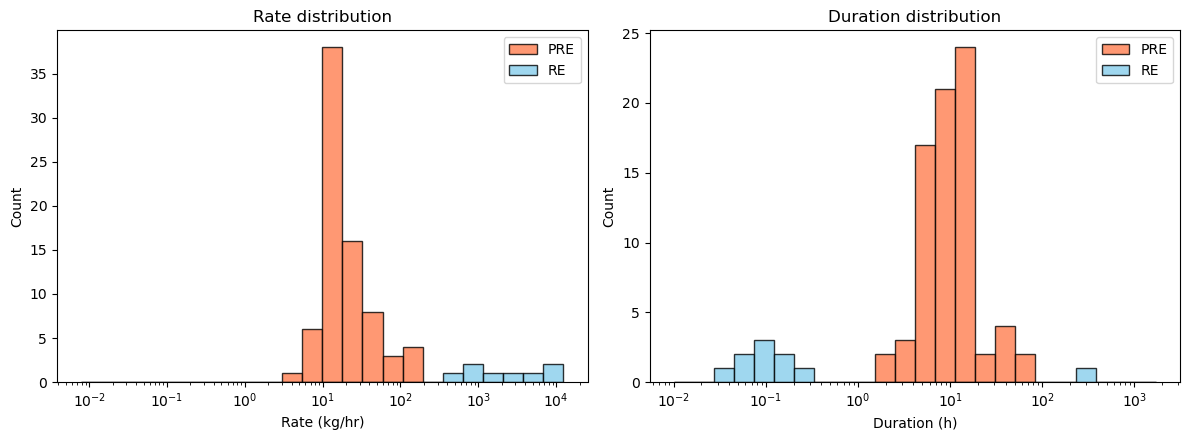

In [11]:
# --- Rate & duration distributions by event type, with the bootstrap Weibull fit overlaid ---
from scipy.stats import weibull_min
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, col, label in zip(axes, ["rate", "duration"], ["Rate (kg/hr)", "Duration (h)"]):
    re_v  = events[events.event_type == "RE"][col].to_numpy(dtype=float)
    pre_v = events[events.event_type == "PRE"][col].to_numpy(dtype=float)
    lo = max(1e-3, min(events[col].min(), 1e-2)); hi = events[col].max()
    bins = np.logspace(np.log10(lo), np.log10(hi), 25)
    ax.hist(pre_v, bins=bins, color="coral",   edgecolor="black", alpha=0.8, label="PRE")
    ax.hist(re_v,  bins=bins, color="skyblue", edgecolor="black", alpha=0.8, label="RE")
    ax.set_xscale("log"); ax.set_xlabel(label); ax.set_ylabel("Count"); ax.legend()
axes[0].set_title("Rate distribution"); axes[1].set_title("Duration distribution")
#fig.suptitle("Case Study 2 — event rate & duration distributions")
fig.tight_layout(); fig.savefig(os.path.join(OUTDIR, "cs2_distributions.png"), dpi=150)
plt.show()

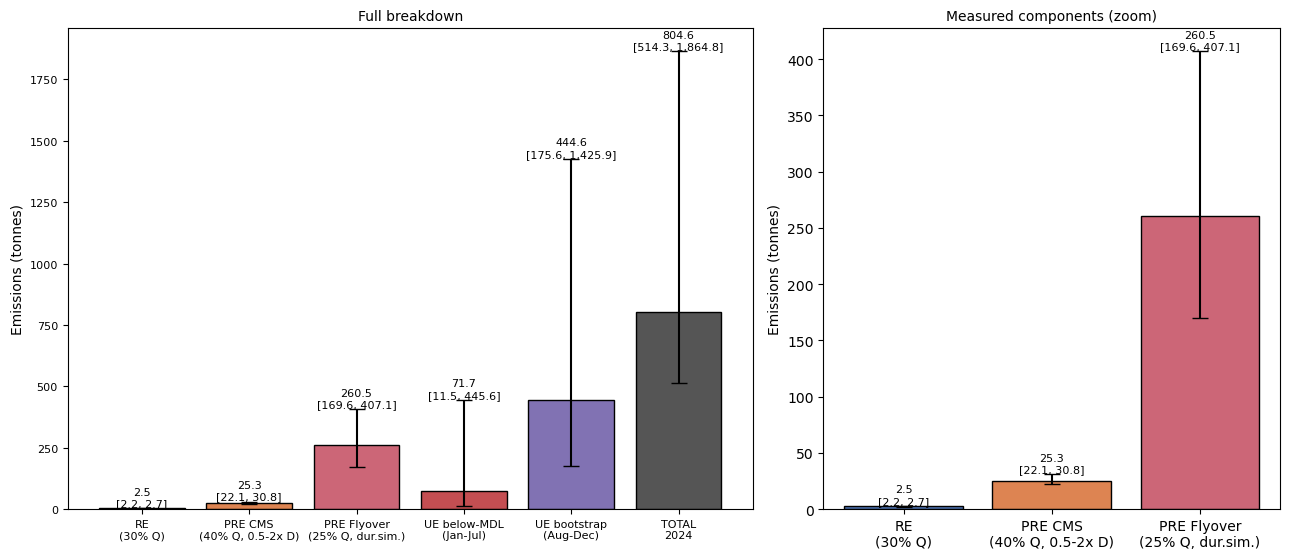

In [12]:
# --- Emissions breakdown (tonnes): per-PRE bounds, PREs via RSS; CIs annotated. ---
# Left = full breakdown; right = zoom on the small measured components so their whiskers are legible.
labels = ["RE\n(30% Q)", "PRE CMS\n(40% Q, 0.5-2x D)", "PRE Flyover\n(25% Q, dur.sim.)",
          "UE below-MDL\n(Jan-Jul)", "UE bootstrap\n(Aug-Dec)", "TOTAL\n2024"]
vals  = np.array([re_meas, cms_meas, fly_meas, ue_mdl, ue_boot, total]) / 1000
lo    = np.array([re_lo, cms_lo, fly_lo, ue_mdl_lo, ue_boot_lo, total_lo]) / 1000
hi    = np.array([re_hi, cms_hi, fly_hi, ue_mdl_hi, ue_boot_hi, total_hi]) / 1000
errlo = np.where(np.isnan(lo), 0.0, vals - lo)
errhi = np.where(np.isnan(hi), 0.0, hi - vals)
yerr  = np.vstack([errlo, errhi])
colors = ["#4C72B0", "#DD8452", "#CC6677", "#C44E52", "#8172B3", "#555555"]

def annotate(ax, idxs, fs=8):
    for x, j in enumerate(idxs):
        top = max(vals[j], hi[j]) if not np.isnan(hi[j]) else vals[j]
        ci  = "" if np.isnan(lo[j]) else f"\n[{lo[j]:,.1f}, {hi[j]:,.1f}]"
        ax.text(x, top, f"{vals[j]:,.1f}{ci}", ha="center", va="bottom", fontsize=fs)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 6), gridspec_kw={"width_ratios": [3, 2]})

allk = list(range(6))
ax1.bar(labels, vals, color=colors, yerr=yerr, capsize=6, edgecolor="black")
ax1.set_ylabel("Emissions (tonnes)")
ax1.set_title("Full breakdown", fontsize=10)
ax1.tick_params(labelsize=8)
annotate(ax1, allk)

k = [0, 1, 2]
zl = ["RE\n(30% Q)", "PRE CMS\n(40% Q, 0.5-2x D)", "PRE Flyover\n(25% Q, dur.sim.)"]
ax2.bar(zl, vals[k], color=[colors[j] for j in k],
        yerr=np.vstack([errlo[k], errhi[k]]), capsize=6, edgecolor="black")
ax2.set_ylabel("Emissions (tonnes)")
ax2.set_title("Measured components (zoom)", fontsize=10)
annotate(ax2, k)

#fig.suptitle("Case Study 2 (redone) - annualized 2024 emissions "
#             "(per-PRE duration uncertainty; PREs aggregated in quadrature / RSS)", fontsize=11)
fig.tight_layout(rect=[0, 0, 1, 0.95])
fig.savefig(os.path.join(OUTDIR, "cs2_emissions_breakdown.png"), dpi=150)
plt.show()


## 10. Export results to CSV

In [13]:
# 1) Regenerated emission events (with obs_kind + flags + estimated/simulated flyover start/end)
events_out = events[["id","equipment_of_record","obs_kind","event_type","rate","duration","quantity",
                     "uncertainties","startTime","endTime","merged_from",
                     "duration_uncertainty_applied","start_end_simulated","sourceLocation",
                     "first_detection","last_detection",
                     "emis_point","emis_lo","emis_hi"]
                    + EST_COLS + SIM_COLS]
events_out.to_csv("emission_events_case_study_2.csv", index=False)

# 1b) Dedicated flyover-only PRE start/end simulation table
fly_sim = events.loc[events["obs_kind"] == "Flyover",
                     ["merged_from","rate"] + EST_COLS + ["duration","quantity"] + SIM_COLS].copy()
fly_sim.to_csv(os.path.join(OUTDIR, "cs2_flyover_pre_simulated_times.csv"), index=False)

# 2) Result summary (the annualized breakdown with 95% bounds)
result_path = os.path.join(OUTDIR, "cs2_results_summary.csv")
summary.to_csv(result_path, index=False)

# 3) Run metadata for provenance
meta = pd.DataFrame([
    ("measured_window",  f"{MEASURED_START.date()} .. {MEASURED_END.date()}"),
    ("bootstrap_window", f"{BOOT_START.date()} .. {YEAR_END.date()}"),
    ("cms_dur_multiplier", f"log-uniform{CMS_DUR_MULT}, symmetric about 1"),
    ("pre_uncertainty_method", "per-PRE bounds x rate, aggregated in quadrature (RSS)"),
    ("cms_point_estimate", "measured (1x); two-sided, M log-uniform 0.5x-2x"),
    ("cms_tech", CMS_TECH), ("bootstrap_fit", BOOT_FIT),
    ("mc_dur", MC_DUR), ("mc_below_mdl", MC_MEASURED), ("mc_bootstrap", MC_BOOT),
    ("seed_ue", SEED_UE),
    ("use_flyover_detection_time", USE_FLYOVER_DETECTION_TIME),
    ("n_RE", int((events.event_type=='RE').sum())),
    ("n_PRE", int((events.event_type=='PRE').sum())),
], columns=["parameter","value"])
meta.to_csv(os.path.join(OUTDIR, "cs2_run_metadata.csv"), index=False)

print("Wrote:")
print("  emission_events_case_study_2.csv  (", len(events_out), "events, incl. simulated flyover start/end )")
print(" ", result_path)
print("  cs2_outputs/cs2_flyover_pre_simulated_times.csv")
print("  cs2_outputs/cs2_run_metadata.csv")
summary[["component","tonnes","lower_tonnes","upper_tonnes"]]

Wrote:
  emission_events_case_study_2.csv  ( 86 events, incl. simulated flyover start/end )
  cs2_outputs/cs2_results_summary.csv
  cs2_outputs/cs2_flyover_pre_simulated_times.csv
  cs2_outputs/cs2_run_metadata.csv


,component,tonnes,lower_tonnes,upper_tonnes
0,Measured RE (operational),2.453516,2.178542,2.728489
1,"Measured PRE - CMS (measured, M~logU 0.5-2x, RSS)",25.330816,22.053229,30.847947
2,Measured PRE - Flyover (duration-simulated),260.466736,169.607747,407.131618
3,Measured RE+PRE (all PREs via quadrature),288.251068,197.332565,435.019940
4,UE below-MDL (measured window),71.709549,11.529529,445.598123
5,UE bootstrap (unmeasured window),444.645112,175.580387,1425.859448
6,"UE total (below-MDL + bootstrap, RSS)",516.354661,240.642019,1566.390013
7,TOTAL annualized 2024,804.605729,514.289290,1864.848787


## 11. Result summary & caveats

The numbers printed above are a faithful run of the toolkit on the new data under the stated
choices. Read them alongside these caveats:

- **CMS duration uncertainty is a DEFAULT ILLUSTRATIVE assumption, not a calibrated model** — the
  duration multiplier `M` is **log-uniform and symmetric about 1** (`CMS_DUR_MULT = (0.5, 2.0)` = its
  95% CI), so a CMS-inferred duration may be shorter *or* longer by up to a factor of two, with the
  point estimate unchanged (M median = 1). This replaces the earlier one-sided `Uniform(1.0, 3.0)`
  (which could only *lengthen* durations, +100% at the median). The 0.5×–2× span is seeded from the
  Daniels et al. (2024) controlled releases but should **not** be treated as universal: real CMS
  duration error depends on sensor layout, meteorology, algorithm and site geometry. Change
  `CMS_DUR_MULT` to widen/narrow the band.
- **Measured-event uncertainty is propagated analytically (Eqs. 3, 6, 10-11)** — per event, the technology-specific
  quantification uncertainty (CMS 40 %, flyover 25 %, operational 30 %) and the duration uncertainty are combined in
  quadrature (Eq. 6), then all events are combined in quadrature (root-sum-square). CMS PREs: point = measured emission,
  relative duration uncertainty +1.0/−0.5 from the log-uniform multiplier M (95% CI 0.5×–2×). Flyover PRE: point = adopted
  **median** quantity, asymmetric relative duration uncertainty from the LPR/NRR duration CI. REs: quantification only. The flyover PRE is **reported on its own line** because it
  dominates and is by far the most uncertain (its 95% duration CI is bounded below by the 44-day merged-detection span).
- **Flyover duration (conditional-on-detection, soft bounds)** — flyover detections placed at their May–Jul *detection times*
  are bounded by the Apr 1 OGI null-detection (valid with probability `NULL_POD`, else the Jan nulls / window start)
  and, with no later null, by the end of the monitored window (31 Jul), producing a multi-month PRE that dominates
  the measured total. The null-repair rate follows Fox et al. (2021) SI Eq. S1 as a per-visit probability
  (`P_MAX = 0.25`, weekly visits); `p_max` is the single most influential assumption for this event (see
  `cs2_sensitivity.py`). Set `USE_FLYOVER_DETECTION_TIME=False` and/or
  `MEASURED_END="2024-04-30"` for the more conservative Jan–Apr framing.
- **Below-MDL over an under-monitored window** — extending the monitored window to July (with no CMS
  data after Apr 30) means the below-MDL sim treats May–Jul as monitored-but-empty and simulates
  sub-MDL misses across those hours (the hours of the flyover PRE itself are excluded from the budget).
- **Time budget** — the POD-based simulation tiles only the gap hours (measured window minus the union
  of observed-event hours; CMS assumed observing throughout, `CMS_COVERAGE = None`). The v1.0 code
  tiled the *sum of observed-event durations* instead, which neither matched the SI description nor the
  monitoring coverage.
- **Below-MDL uses empirical inputs** — the toolkit samples component leak rates from
  `sample_leak_rate.csv` (Rutherford et al.) and empirical event durations. There is no lognormal
  fit hook on the below-MDL path, so the "lognormal for below-MDL" preference does not apply there;
  the bootstrap uses the Weibull fit as requested.
- **Bootstrap tail** — the Weibull fit and high `poe` (~0.7) are inherited from the same PRE
  durations, so the Aug–Dec estimate is large and wide. Reducing the flyover artifact lowers this too.
- **RSS of *independent* per-event errors narrows the aggregate by ~1/√N.** The CMS band is small
  (≈ −2/+5 t on 24 t across 75 PREs) *by construction*, even though each event spans a factor of two — the errors
  partially cancel when summed in quadrature. This is the correct treatment IF CMS duration errors are
  independent/random. If instead the 0.5×–2× multiplier represents a **systematic** CMS bias (all durations
  biased the same way), the per-event bounds should sum **linearly** (correlated), giving CMS ≈
  [11.9, 47.6] t. The flyover duration uncertainty is propagated into the **measured** band only; the
  bootstrap still fits its Weibull to the adopted point duration.
  The flyover PRE duration is now inferred *conditional on the detection(s)* (onset/cessation sampled from truncated hazards that must contain the detection span; `t_SND = last detection + 90 d`), so it is no longer pinned to the null-detection bracket. Any remaining length reflects genuine onset uncertainty over the long pre-detection window (weak LPR), not the former bracket-filling fallback.


## 12. Write markdown results doc (for the paper)

In [14]:
# Gather all paper-ready statistics and write a markdown summary.
re_df  = events[events.event_type == "RE"]
pre_df = events[events.event_type == "PRE"]
cms_df = pre_df[pre_df.obs_kind == "CMS"]
fly_df = pre_df[pre_df.obs_kind == "Flyover"]

n_cms_obs  = len(cms)
n_fly_det  = int(fly["detection"].sum());  n_fly_null = int((~fly["detection"].astype(bool)).sum())
n_ogi_det  = int(ogi["detection"].sum());  n_ogi_null = int((~ogi["detection"].astype(bool)).sum())
n_op_obs   = len(op)

fly_row = fly_df.iloc[0] if len(fly_df) else None
def d(x):  return pd.to_datetime(x).date()

L = []
L.append("# Case Study No. 2 — Results Summary (EAMEET v1.0, redone)\n")
L.append(f"*Site A, calendar year 2024. Hybrid estimation: below-MDL over the measured window "
         f"({d(MEASURED_START)} – {d(MEASURED_END)}) + bootstrap over the unmeasured window "
         f"({d(BOOT_START)} – {d(YEAR_END)}).*\n")

L.append("## 1. Configuration\n")
L.append("| Parameter | Value |")
L.append("|---|---|")
L.append(f"| Measured window | {d(MEASURED_START)} – {d(MEASURED_END)} |")
L.append(f"| Unmeasured (bootstrap) window | {d(BOOT_START)} – {d(YEAR_END)} |")
L.append(f"| Quantification uncertainty | CMS {UNC_PCT['CMS']:.0%}, Flyover {UNC_PCT['Flyover']:.0%}, Operational {UNC_PCT['Operational']:.0%} |")
L.append(f"| CMS PRE duration uncertainty | M~log-uniform, symmetric about 1, 95% CI {CMS_DUR_MULT} (illustrative, Daniels et al. 2024) |")
L.append(f"| Flyover PRE duration workflow | LPR {LPR}/day; NRR = Fox et al. (2021) Eq. S1 per visit (p_max {P_MAX}, V {VISIT_INTERVAL_DAYS} d, {LEAKS_PER_SITE} leaks/site); t_SND = {'end of monitored window' if SND_CAP == 'measured_end' else f'last detection + {SND_EXTENSION_DAYS} d'}; N={N_DUR_SIM:,}, adopted **{FLYOVER_DURATION_STAT}**; null-detection POD {NULL_POD} (soft bounds) |")
L.append(f"| Below-MDL technology / iters | {CMS_TECH} / {MC_MEASURED} |")
L.append(f"| Below-MDL time budget | {budget_h:,.0f} gap h of {window_h:,.0f} h (CMS coverage: {'whole window' if CMS_COVERAGE is None else 'uptime intervals'}; superseded sum-of-durations budget {legacy_h:,.0f} h) |")
L.append(f"| Bootstrap fit / iters | {BOOT_FIT} / {MC_BOOT} |")

L.append("\n## 2. Observations and event creation\n")
L.append("| Observation type | Count | Role |")
L.append("|---|---|---|")
L.append(f"| CMS | {n_cms_obs} | quantified detections -> PRE (per equipment) |")
L.append(f"| Flyover | {n_fly_det + n_fly_null} ({n_fly_det} detections, {n_fly_null} non-detection) | facility PRE + null-detect |")
L.append(f"| OGI | {n_ogi_det + n_ogi_null} ({n_ogi_det} detections, {n_ogi_null} non-detection) | non-detections = null markers; detections excluded (no rate) |")
L.append(f"| Operational | {n_op_obs} | Resolved Events (quantity from record) |")
L.append(f"\n**Emission events created: {len(events)}** — **{len(re_df)} Resolved (RE)**, "
         f"**{len(pre_df)} Partially Resolved (PRE)**.")
L.append(f"- PRE composition: **{len(cms_df)} CMS-derived**, **{len(fly_df)} flyover-only** "
         f"(flagged `start_end_simulated`).")
L.append(f"- OGI true-detections excluded (no quantification): {ogi_excluded}\n")

L.append("## 3. Event statistics (median rate & duration)\n")
L.append("| Event type | n | Median rate (kg/hr) | Median duration (h) |")
L.append("|---|---|---|---|")
L.append(f"| RE (operational) | {len(re_df)} | {re_df.rate.median():.2f} | {re_df.duration.median():.2f} |")
L.append(f"| PRE — all | {len(pre_df)} | {pre_df.rate.median():.2f} | {pre_df.duration.median():.2f} |")
L.append(f"| PRE — CMS | {len(cms_df)} | {cms_df.rate.median():.2f} | {cms_df.duration.median():.2f} |")
L.append(f"| PRE — flyover | {len(fly_df)} | {fly_df.rate.median():.2f} | {fly_df.duration.median():.2f} |")

L.append("\n## 4. Emissions by event type (measured window)\n")
L.append(f"*Per event, the technology-specific quantification uncertainty (CMS {UNC_PCT['CMS']:.0%}, flyover "
         f"{UNC_PCT['Flyover']:.0%}, operational {UNC_PCT['Operational']:.0%}) and the duration uncertainty are "
         "combined in quadrature per event (Eq. 6); events are then aggregated in **quadrature (root-sum-square)** "
         "(Eqs. 10-11). CMS PRE: point = measured emission, relative duration uncertainty +1.0/−0.5 from the "
         "log-uniform multiplier M (95% CI 0.5×–2×). Flyover PRE: point = adopted median, asymmetric relative "
         "duration uncertainty from the LPR/NRR duration CI. RE: quantification only (Eq. 3).*\n")
L.append("| Component | Emissions (t) | 95% CI (t) |")
L.append("|---|---|---|")
L.append(f"| Measured RE (operational, {UNC_PCT['Operational']:.0%} Q) | {re_meas/1000:.2f} | [{re_lo/1000:.2f}, {re_hi/1000:.2f}] |")
L.append(f"| Measured PRE — CMS (measured, M~logU 0.5-2x, RSS) | {cms_meas/1000:.2f} | [{cms_lo/1000:.2f}, {cms_hi/1000:.2f}] |")
L.append(f"| Measured PRE — Flyover (duration-simulated) | {fly_meas/1000:.2f} | [{fly_lo/1000:.2f}, {fly_hi/1000:.2f}] |")
L.append(f"| **Measured RE+PRE total** | **{measured/1000:.2f}** | [{measured_lo/1000:.2f}, {measured_hi/1000:.2f}] |")
cms_base = float((cms_df.rate * cms_df.duration).sum())
L.append(f"\n- CMS PRE: point = measured emission **{cms_base/1000:.2f} t** (= sum of rate×measured-duration "
         f"over {len(cms_df)} PREs); per-event uncertainty combines {UNC_PCT['CMS']:.0%} quantification with the "
         f"two-sided duration uncertainty from a log-uniform multiplier M (95% CI "
         f"{CMS_DUR_MULT[0]}×–{CMS_DUR_MULT[1]}×, centred on 1), aggregated in quadrature -> "
         f"**[{cms_lo/1000:.2f}, {cms_hi/1000:.2f}] t**. RSS of {len(cms_df)} independent per-event errors "
         f"narrows the band (~1/√N); a correlated/systematic error shared by all CMS events would instead give "
         f"[{cms_sys_lo/1000:.2f}, {cms_sys_hi/1000:.2f}] t (linear sum).")
L.append(f"- **Flyover PRE**: point {fly_meas/1000:.1f} t; its {UNC_PCT['Flyover']:.0%} quantification uncertainty and 95% duration CI map to a "
         f"**{fly_lo/1000:.1f}–{fly_hi/1000:.1f} t** emissions range, which dominates the measured PRE "
         f"band — hence the separate line and the wide whisker in the figure.")

L.append("\n## 5. Flyover-only PRE — simulated start/end (LPR/NRR workflow)\n")
if fly_row is not None:
    L.append(f"Merged observations **{fly_row['merged_from']}**, rate {fly_row['rate']:.1f} kg/hr.\n")
    L.append("| Quantity | Start | End | Duration (h) | Emission (t) |")
    L.append("|---|---|---|---|---|")
    L.append(f"| Estimated (null-detect bracket) | {d(fly_row['estimated_start'])} | {d(fly_row['estimated_end'])} | "
             f"{fly_row['estimated_duration_h']:.0f} | {fly_row['estimated_quantity']/1000:.1f} |")
    L.append(f"| Simulated — median | {d(fly_row['sim_start_time'])} | {d(fly_row['sim_end_time'])} | "
             f"{fly_row['sim_duration_h']:.0f} | {fly_row['rate']*fly_row['sim_duration_h']/1000:.1f} |")
    L.append(f"| Simulated — mean | — | — | {fly_row['sim_duration_mean_h']:.0f} | "
             f"{fly_row['rate']*fly_row['sim_duration_mean_h']/1000:.1f} |")
    L.append(f"| Simulated 95% CI | start [{d(fly_row['sim_start_lo'])}, {d(fly_row['sim_start_hi'])}] | "
             f"end [{d(fly_row['sim_end_lo'])}, {d(fly_row['sim_end_hi'])}] | "
             f"[{fly_row['sim_duration_lo']:.0f}, {fly_row['sim_duration_hi']:.0f}] | — |")
    L.append(f"\n**Adopted into the total: `{FLYOVER_DURATION_STAT}` -> "
             f"{fly_row['duration']:.0f} h, {fly_row['quantity']/1000:.1f} t.**")

L.append("\n## 6. Unresolved emissions (UE)\n")
L.append("| UE component | Window | Emissions (t) | 95% CI (t) |")
L.append("|---|---|---|---|")
L.append(f"| Below-MDL ({CMS_TECH}) | {d(MEASURED_START)}–{d(MEASURED_END)} | {ue_mdl/1000:.2f} | [{ue_mdl_lo/1000:.2f}, {ue_mdl_hi/1000:.2f}] |")
L.append(f"| Bootstrap ({BOOT_FIT}, poe={poe:.3f}) | {d(BOOT_START)}–{d(YEAR_END)} | {ue_boot/1000:.2f} | [{ue_boot_lo/1000:.2f}, {ue_boot_hi/1000:.2f}] |")
L.append(f"| **Total UE** | 2024 | **{ue_total/1000:.2f}** | [{ue_total_lo/1000:.2f}, {ue_total_hi/1000:.2f}] |")

L.append("\n## 7. Full-year 2024 annualized total\n")
L.append("| Component | Emissions (t) | 95% CI (t) |")
L.append("|---|---|---|")
for _, row in summary.iterrows():
    ci = "—" if pd.isna(row["lower_kg"]) else f"[{row['lower_tonnes']:.2f}, {row['upper_tonnes']:.2f}]"
    L.append(f"| {row['component']} | {row['tonnes']:.2f} | {ci} |")
L.append(f"\n**TOTAL annualized 2024 = {total/1000:.1f} t (95% CI {total_lo/1000:.0f}–{total_hi/1000:.0f} t).**")
L.append(f"Measured share {measured/total:.0%}; UE share {(ue_mdl+ue_boot)/total:.0%}.\n")

L.append("## 8. Notes & sensitivities\n")
L.append(f"- Flyover-only PRE(s) dominate measured PRE. Point estimate = `{FLYOVER_DURATION_STAT}` of the "
         f"LPR/NRR duration workflow; its 95% duration CI is converted to asymmetric emission bounds and "
         f"**combined with the CMS PRE bounds in quadrature (RSS)**, then reported separately. Every draw "
         f"contains the detection span; the onset extension uses the repair-minus-onset hazard and the "
         f"preceding null detection is a valid bound only with probability {NULL_POD} (else the chain of "
         f"earlier nulls / window start), so the band reflects both the survival constraint and the "
         f"reliability of the null detections.")
L.append("- Below-MDL samples empirical component leaks (Rutherford et al.) + empirical event durations "
         "(no lognormal-fit hook). Bootstrap uses the Weibull fit.")
L.append("- CMS PRE duration uncertainty is a DEFAULT ILLUSTRATIVE assumption (Daniels et al. 2024, not "
         "universal): a log-uniform multiplier M symmetric about 1 (95% CI 0.5×–2×), so the band is "
         "two-sided with the point estimate = measured emission. Per-event bounds are aggregated in "
         "quadrature (RSS), so the independent aggregate band is narrow (~1/√N); a systematic CMS bias "
         "would sum linearly instead.")

doc = "\n".join(L) + "\n"
doc_path = os.path.join(OUTDIR, "Case_study_2_results_summary.md")
with open(doc_path, "w") as f:
    f.write(doc)
print("Wrote", doc_path, f"({len(doc)} chars)")
print("\n" + doc)

Wrote cs2_outputs/Case_study_2_results_summary.md (6382 chars)

# Case Study No. 2 — Results Summary (EAMEET v1.0, redone)

*Site A, calendar year 2024. Hybrid estimation: below-MDL over the measured window (2024-01-01 – 2024-07-31) + bootstrap over the unmeasured window (2024-08-01 – 2024-12-31).*

## 1. Configuration

| Parameter | Value |
|---|---|
| Measured window | 2024-01-01 – 2024-07-31 |
| Unmeasured (bootstrap) window | 2024-08-01 – 2024-12-31 |
| Quantification uncertainty | CMS 40%, Flyover 25%, Operational 30% |
| CMS PRE duration uncertainty | M~log-uniform, symmetric about 1, 95% CI (0.5, 2.0) (illustrative, Daniels et al. 2024) |
| Flyover PRE duration workflow | LPR 0.006/day; NRR = Fox et al. (2021) Eq. S1 per visit (p_max 0.25, V 7 d, 10 leaks/site); t_SND = end of monitored window; N=100,000, adopted **median**; null-detection POD {'ogi': 0.9, 'flyover': 0.9} (soft bounds) |
| Below-MDL technology / iters | Qube / 10000 |
| Below-MDL time budget | 2,231 gap h of 5,1